# Principles of AI

**DCS 404 · Data Science and Machine Learning**

---

What does it actually mean for a program to be *intelligent*? Before this course builds a single
machine-learning model, this module answers that question. It covers what AI is, where machine learning fits
inside it, what an **intelligent agent** is, and how an agent can think ahead by treating a problem as a
**search** through possible futures.

The running example is **Tic-Tac-Toe**. It's small enough to understand completely, and yet it already has
over a quarter of a million possible games. That **combinatorial explosion** is the reason AI needs clever
algorithms rather than brute force, and it sets up the next module.

This notebook covers the Week 3 reading, *Artificial Intelligence and Machine Learning Fundamentals* (Nagy,
2018), **Chapter 1 — Principles of AI**. Chapter 2 is the next module, **Search and Games**.

## How to work through this

Run every code cell in order (`Shift + Enter`). Section 5 builds the Tic-Tac-Toe helpers (`winner`,
`all_moves`, `draw_board`, …), and the next module reuses them.

**Reading alongside the textbook:**

| This notebook | Textbook, Chapter 1 |
|---|---|
| 1. What AI is | pp. 1–8 |
| 2. Intelligent agents | pp. 7–8, 16 |
| 3. Python and NumPy | pp. 9–15 (Exercise 1) |
| 4. BFS and DFS | pp. 17–20 |
| 5. The Tic-Tac-Toe state space | pp. 20–27 (Exercises 2–3, Activity 1) |

The book's code has a few bugs, some of which change the answer. This notebook fixes them as it goes, and
Section 6 lists every correction.

Nothing here needs a library beyond NumPy and Matplotlib.

## Learning objectives

After completing this module you will be able to:

- Define AI and machine learning (Samuel's and Mitchell's definitions), and explain why **AI ⊃ ML**: why
  rule-based and search-based agents count as AI with no learning at all.
- Name the main fields of AI and the disciplines it draws on, and describe the Turing test.
- Describe an **intelligent agent** (sensors, actuators, goal, performance measure) and write one as a
  function from percepts to actions.
- Use NumPy for basic matrix operations, and handle floating-point results correctly.
- Model a problem as a **state space** (initial state, successor function, goal test) and explore it with
  **breadth-first** and **depth-first search**.
- Represent a game in code, and measure the **combinatorial explosion** of its state space by counting every
  possible game exactly.

## Setup

Run this once. It loads the libraries, sets the usual plotting style, and fixes a random seed so every
simulated game comes out the same each time you run it.

In [1]:
import math
import heapq
import random
import time
from collections import deque, Counter
from itertools import permutations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
RANDOM_STATE = 0
rng = random.Random(RANDOM_STATE)

# Set to True to play against the AIs yourself (uses input(); leave False when running all cells)
INTERACTIVE = False
print("Ready.")

Ready.


---
## 1. What is AI, and how is it different from machine learning?

The textbook starts with three definitions worth knowing by heart:

> **Artificial Intelligence** is a science that's used to construct intelligence using hardware and software
> solutions.

> **Machine learning** is a field of study concerned with giving computers the ability to learn without being
> explicitly programmed. *(Arthur Samuel, 1959)*

> A computer program is said to **learn** from experience $E$ with respect to a task $T$ and a performance
> measure $P$, if its performance on $T$, as measured by $P$, improves with experience $E$.
> *(Tom Mitchell, 1997)*

Mitchell's definition is the useful one, because you can check it. Spam filtering: $T$ = label emails,
$P$ = accuracy, $E$ = a pile of emails humans have already labelled. Every model in the later modules of this
course fits that pattern.

Now the key point. **You can build AI without machine learning.** If you hard-code rules, or search through
possible futures, your program can act intelligently with no experience $E$ at all. All of this module works
that way:

| Approach | Where the "intelligence" comes from | Example in this course |
|---|---|---|
| **Rules** | A human writes them down | Next module: "if you can win, win; if they can win, block" |
| **Search** | Looking ahead at possible futures | Next module: A*, Minimax |
| **Machine learning** | Patterns found in data | Regression, Decision Trees, K-Means, Neural Networks |

### Why it takes many disciplines

A self-driving car has to *sense* other cars (computer vision), *predict* where they'll go (statistics),
*plan* a route (graph theory and search), and *move* the wheels (control theory and robotics). The book lists
the disciplines AI borrows from: robotics, algorithm theory, statistics, psychology, software engineering,
mathematics, control theory, information theory, graph theory, physics, and computer graphics.

### Fields of AI, by the human ability they copy

| Human ability | AI field | Everyday example |
|---|---|---|
| Listening and speaking | Speech recognition and synthesis | Voice assistants, live translation |
| Understanding language | Natural Language Processing (NLP) | Chatbots, search engines |
| Remembering things | Knowledge bases and ontologies | Google's Knowledge Graph |
| Thinking | Expert systems, neural networks | Medical diagnosis support |
| Seeing | Computer vision | Face unlock, medical imaging |
| Moving | Robotics and control theory | Warehouse robots, drones |

### The Turing test

Alan Turing proposed testing intelligence by conversation. A judge chats by text with a human and a machine.
If the judge can't reliably tell which is which, the machine passes. The textbook (2018) predicted this
wouldn't happen until "the late 2020s". **That prediction has aged fast.** In a 2025 study (Jones & Bergen),
judges picked GPT-4.5 as the human 73% of the time when it was prompted to adopt a persona. Large language
models have changed this part of the field more than any other since the book was written. The *Total*
Turing test, which adds vision and physical movement, is still far off.

### Two kinds of reasoning, two kinds of learning

- **Classification** works out what category something belongs to ("Jane is female and a parent, so Jane is
  a mother"). **Prediction** estimates something from patterns ("someone who buys organic milk is more likely
  to buy organic yoghurt").
- **Supervised learning** learns from labelled examples (Regression, Logistic Regression, Decision Trees,
  KNN). **Unsupervised learning** finds structure without labels (K-Means). Both get full modules later in
  the course.

---
## 2. Intelligent agents

The central object in AI (and in this module) is the **agent**. The textbook defines an intelligent agent as
something that:

- is **autonomous**,
- **observes** its surroundings through **sensors**,
- **acts** on its environment through **actuators**, and
- directs its activity toward a **goal**.

Put simply: **an agent is a function from what it perceives to what it does.** Let's write one. Here is the
classic *vacuum world*: two rooms, `A` and `B`, each either clean or dirty. The vacuum's sensors tell it which
room it's in and whether that room is dirty. Its actuators can `Suck`, or move `Left` / `Right`.

In [2]:
def reflex_vacuum_agent(percept):
    '''A simple reflex agent: the action depends only on the current percept.'''
    location, is_dirty = percept
    if is_dirty:
        return "Suck"
    return "Right" if location == "A" else "Left"

def run_vacuum_world(agent, dirt, location="A", steps=6):
    dirt = dict(dirt)                                   # don't mutate the caller's dict
    score = 0
    for t in range(steps):
        percept = (location, dirt[location])            # sensors
        action = agent(percept)                         # the agent decides
        if action == "Suck" and dirt[location]:         # actuators change the world
            dirt[location] = False
            score += 10                                 # reward for cleaning
        elif action in ("Left", "Right"):
            location = "A" if action == "Left" else "B"
            score -= 1                                  # small cost for moving
        print(f"t={t}  percept={percept!s:<14} action={action:<6} world={dirt}")
    print(f"Performance score: {score}")

run_vacuum_world(reflex_vacuum_agent, dirt={"A": True, "B": True})

t=0  percept=('A', True)    action=Suck   world={'A': False, 'B': True}
t=1  percept=('A', False)   action=Right  world={'A': False, 'B': True}
t=2  percept=('B', True)    action=Suck   world={'A': False, 'B': False}
t=3  percept=('B', False)   action=Left   world={'A': False, 'B': False}
t=4  percept=('A', False)   action=Right  world={'A': False, 'B': False}
t=5  percept=('B', False)   action=Left   world={'A': False, 'B': False}
Performance score: 16


Both rooms are clean after three steps, and the agent never "learned" anything. Its designer wrote the rules
in advance. Two ideas from this toy come back in every later section:

1. **Performance measure.** We judged the agent by a score (+10 per clean, −1 per move). The textbook calls
   this the "carrot and stick": good actions are rewarded and bad ones punished. A game AI's goal is the same
   in principle: get the highest score, where winning is the top score.
2. **The agent wastes moves.** After both rooms are clean it keeps going back and forth (`Left`, `Right`, …),
   because a *reflex* agent can't think ahead. Agents that **look ahead** at the consequences of their actions
   are what the rest of this module builds.

---
## 3. Python and NumPy warm-up (textbook Exercise 1)

The book uses Python because it is readable, quick to write, and has the best set of AI/ML libraries: NumPy,
SciPy, pandas, scikit-learn, NLTK, TensorFlow, PyTorch. You met NumPy on DataCamp in Week 2. Here is the
book's Exercise 1, *updated*: the book uses `np.mat`, which **was removed in NumPy 2.0**. Use a normal
`np.array` and the `@` operator for matrix multiplication.

In [3]:
A = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 9]])

print("A @ A  (matrix product, i.e. the 'square' of A):")
print(A @ A)
print("\nA * A  (element-wise -- NOT the matrix product, a classic mistake):")
print(A * A)
print("\nTranspose A.T:")
print(A.T)
print(f"\nnp.linalg.det(A) = {np.linalg.det(A)!r}")
print(f"Exact determinant by hand: {1*5*9 + 2*6*7 + 3*4*8 - 1*6*8 - 2*4*9 - 3*5*7}")

A @ A  (matrix product, i.e. the 'square' of A):
[[ 30  36  42]
 [ 66  81  96]
 [102 126 150]]

A * A  (element-wise -- NOT the matrix product, a classic mistake):
[[ 1  4  9]
 [16 25 36]
 [49 64 81]]

Transpose A.T:
[[1 4 7]
 [2 5 8]
 [3 6 9]]

np.linalg.det(A) = np.float64(-9.51619735392994e-16)
Exact determinant by hand: 0


Two lessons:

- `@` is matrix multiplication. `*` multiplies cell by cell. The top-left cell of `A @ A` is
  $1\cdot1 + 2\cdot4 + 3\cdot7 = 30$: row 1 of $A$ dotted with column 1 of $A$.
- The determinant is exactly **0** (row 3 − row 2 = row 2 − row 1, so the rows are linearly dependent). NumPy
  returns a tiny non-zero number instead. That's **floating-point rounding**, not a bug. Never test float
  results with `==`; use `np.isclose`.

In [4]:
print(np.linalg.det(A) == 0)          # False -- rounding error
print(np.isclose(np.linalg.det(A), 0))  # True  -- the right way to compare floats

False
True


---
## 4. Problems as search: breadth-first and depth-first search

To make an agent look ahead, we describe the problem as a **state space**:

- an **initial state**, where we start;
- a **successor function** `succ(state)`, the states reachable in one action;
- a **goal test**, which says whether we're done.

Starting at the initial state and applying `succ` over and over builds a **search tree**. The root is the
start, each edge is an action, and leaves are states with no successors. **Search algorithms differ only in
the order they visit the tree.**

The book's toy problem: start at `1`. Each step adds **1 or 2**. Stop at **5**.

In [5]:
def succ(node):
    value, depth = node
    if value == 5:
        return []                                   # goal: a leaf
    if value == 4:
        return [(5, depth + 1)]                     # can't jump past 5
    return [(value + 1, depth + 1), (value + 2, depth + 1)]

root = (1, 1)   # (value, depth)

def bfs_tree(root):
    to_visit = deque([root])          # a QUEUE: first in, first out
    visited = []
    while to_visit:
        node = to_visit.popleft()
        visited.append(node)
        to_visit.extend(succ(node))
    return visited

def dfs_tree(root):
    to_visit = [root]                 # a STACK: last in, first out
    visited = []
    while to_visit:
        node = to_visit.pop()
        visited.append(node)
        to_visit.extend(succ(node))
    return visited

bfs_order, dfs_order = bfs_tree(root), dfs_tree(root)
print("BFS visits (value, depth):", bfs_order)
print("DFS visits (value, depth):", dfs_order)

BFS visits (value, depth): [(1, 1), (2, 2), (3, 2), (3, 3), (4, 3), (4, 3), (5, 3), (4, 4), (5, 4), (5, 4), (5, 4), (5, 5)]
DFS visits (value, depth): [(1, 1), (3, 2), (5, 3), (4, 3), (5, 4), (2, 2), (4, 3), (5, 4), (3, 3), (5, 4), (4, 4), (5, 5)]


The **only** difference between the two functions is `popleft()` (queue) versus `pop()` (stack). It's easier
to see on the tree itself. The number in each node's corner is the order it was visited:

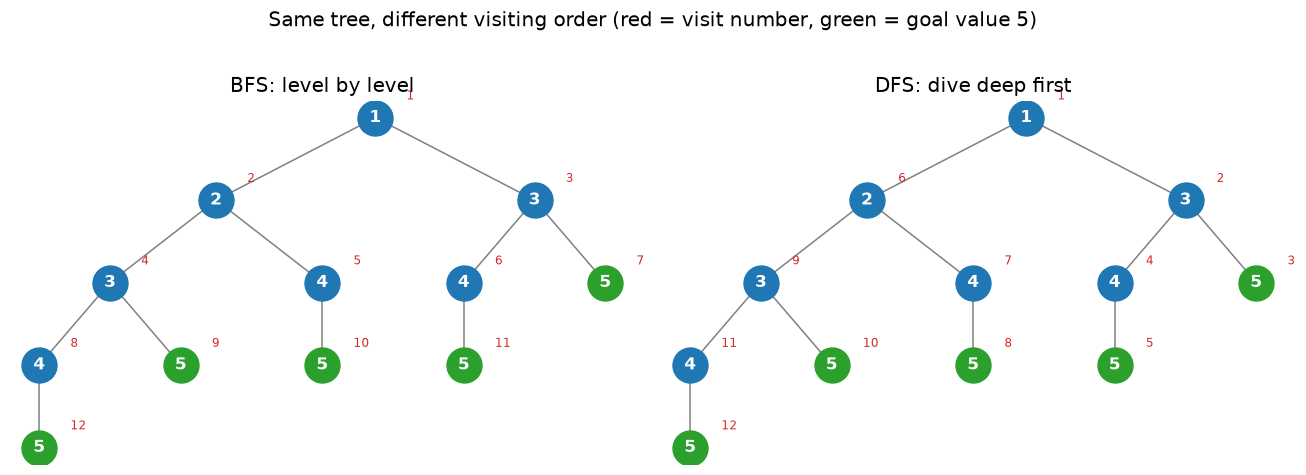

In [6]:
def build_tree(node, path=()):
    '''Return a nested dict {'node': (value, depth), 'id': path, 'children': [...]}.'''
    return {"node": node, "id": path,
            "children": [build_tree(c, path + (i,)) for i, c in enumerate(succ(node))]}

def layout(tree, x=0.0, positions=None):
    '''Assign x positions so leaves are evenly spaced; returns (positions, next_free_x).'''
    positions = {} if positions is None else positions
    if not tree["children"]:
        positions[tree["id"]] = (x, -tree["node"][1]); return positions, x + 1
    xs = []
    for ch in tree["children"]:
        positions, x = layout(ch, x, positions); xs.append(positions[ch["id"]][0])
    positions[tree["id"]] = (sum(xs) / len(xs), -tree["node"][1])
    return positions, x

def visit_rank(tree, order_fn):
    '''Map each tree-node id to its visit number under BFS/DFS (same traversal, on ids).'''
    ranks, frontier = {}, deque([tree]) if order_fn == "bfs" else [tree]
    while frontier:
        t = frontier.popleft() if order_fn == "bfs" else frontier.pop()
        ranks[t["id"]] = len(ranks) + 1
        frontier.extend(t["children"])
    return ranks

def draw_tree(tree, ranks, ax, title):
    pos, _ = layout(tree)
    def edges(t):
        for ch in t["children"]:
            (x0, y0), (x1, y1) = pos[t["id"]], pos[ch["id"]]
            ax.plot([x0, x1], [y0, y1], color="grey", lw=1, zorder=1); edges(ch)
    edges(tree)
    def nodes(t):
        x, y = pos[t["id"]]; v = t["node"][0]
        ax.scatter(x, y, s=520, color="tab:green" if v == 5 else "tab:blue", zorder=2)
        ax.text(x, y, str(v), ha="center", va="center", color="white", fontweight="bold", zorder=3)
        ax.text(x + 0.22, y + 0.22, str(ranks[t["id"]]), fontsize=8, color="tab:red", zorder=3)
        for ch in t["children"]: nodes(ch)
    nodes(tree)
    ax.set_title(title); ax.axis("off")

tree = build_tree(root)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
draw_tree(tree, visit_rank(tree, "bfs"), axes[0], "BFS: level by level")
draw_tree(tree, visit_rank(tree, "dfs"), axes[1], "DFS: dive deep first")
plt.suptitle("Same tree, different visiting order (red = visit number, green = goal value 5)", y=1.02)
plt.tight_layout(); plt.show()

- **BFS** visits level by level, so the **first goal it reaches is the shallowest one**. Here that's 5 at
  depth 3 (`1 → 3 → 5`). For problems where every step costs the same, BFS finds a shortest path.
- **DFS** dives straight down one branch first. It uses little memory but doesn't guarantee the shortest
  path. In a huge tree like chess it can get lost down one very deep branch.

**Trees vs graphs.** If two different paths can reach the *same* state (and in Tic-Tac-Toe they can), you
should keep a **visited set** and skip states you've already seen. Otherwise you do the same work again and
again. The next module's pathfinding section shows exactly how much that costs.

---
## 5. The state space of Tic-Tac-Toe

Two players take turns on a 3×3 board. `X` moves first. Three in a row, column, or diagonal wins. Like the
book, we store the board as a **9-character string**, cells indexed like this:

```
 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | 7 | 8
```

Our AI plays `X` and moves first. The opponent plays `O`.

In [7]:
EMPTY, AI, OPP = ".", "X", "O"
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8),      # rows
         (0, 3, 6), (1, 4, 7), (2, 5, 8),      # columns
         (0, 4, 8), (2, 4, 6)]                 # diagonals

def other(sign):
    return OPP if sign == AI else AI

def winner(board):
    '''Return 'X' or 'O' if someone has three in a line, else EMPTY.'''
    for i, j, k in LINES:
        if board[i] == board[j] == board[k] != EMPTY:
            return board[i]
    return EMPTY

def is_over(board):
    return winner(board) != EMPTY or EMPTY not in board

def all_moves(board, sign):
    '''The successor function: every board reachable by `sign` placing one mark.'''
    return [board[:i] + sign + board[i + 1:] for i, c in enumerate(board) if c == EMPTY]

def print_board(board):
    for r in range(3):
        print(" " + " | ".join(board[3 * r:3 * r + 3]))
    print()

def draw_board(board, ax, title="", values=None):
    '''Draw a board; optional `values` (len 9) are printed small in empty cells (used for heuristics).'''
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect("equal"); ax.axis("off")
    for k in (1, 2):
        ax.plot([k, k], [0, 3], color="black", lw=2); ax.plot([0, 3], [k, k], color="black", lw=2)
    for i, c in enumerate(board):
        x, y = i % 3 + 0.5, 2.5 - i // 3
        if c != EMPTY:
            ax.text(x, y, c, ha="center", va="center", fontsize=28, fontweight="bold",
                    color="tab:blue" if c == AI else "tab:red")
        elif values is not None:
            ax.text(x, y, str(values[i]), ha="center", va="center", fontsize=13, color="tab:green")
        else:
            ax.text(x + 0.33, y - 0.33, str(i), fontsize=8, color="lightgrey")
    ax.set_title(title, fontsize=11)

example = "X...O...X"        # the book's example: X at 0, O at 4, X at 8
print_board(example)
print("winner:", repr(winner(example)), "| game over:", is_over(example))
print("O's possible next boards:", all_moves(example, OPP))

 X | . | .
 . | O | .
 . | . | X

winner: '.' | game over: False
O's possible next boards: ['XO..O...X', 'X.O.O...X', 'X..OO...X', 'X...OO..X', 'X...O.O.X', 'X...O..OX']


### How big is the game? (textbook Exercise 2)

A rough upper bound: the first player has 9 choices, the second 8, then 7, … so at most
$9! = 362{,}880$ move sequences. Many games end early with a win, so the true number is smaller. We don't
have to estimate it, though. A short recursive search can **count every possible game exactly**:

In [8]:
def count_games(board=EMPTY * 9, turn=AI):
    '''Exhaustively play out every legal game; return a Counter of outcomes.'''
    w = winner(board)
    if w != EMPTY:
        return Counter({w: 1})
    if EMPTY not in board:
        return Counter({"draw": 1})
    total = Counter()
    for nxt in all_moves(board, turn):
        total += count_games(nxt, other(turn))
    return total

t0 = time.time()
outcomes = count_games()
print(f"9! upper bound:       {math.factorial(9):,}")
print(f"Actual distinct games: {sum(outcomes.values()):,}   ({time.time() - t0:.1f}s)")
print(f"  X (first player) wins: {outcomes['X']:,}")
print(f"  O (second player) wins: {outcomes['O']:,}")
print(f"  draws:                  {outcomes['draw']:,}")

9! upper bound:       362,880
Actual distinct games: 255,168   (0.6s)
  X (first player) wins: 131,184
  O (second player) wins: 77,904
  draws:                  46,080


That's **255,168** possible games for a game children solve at the kitchen table. Our numbers match the
research figures the book quotes (131,184 / 77,904 / 46,080). Here is how fast the tree grows, move by move:

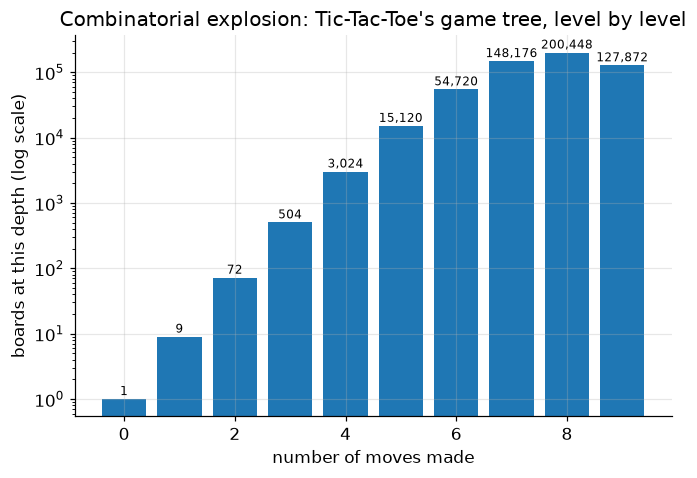

In [9]:
def states_per_depth():
    level, sizes = [EMPTY * 9], [1]
    for step in range(9):
        sign = AI if step % 2 == 0 else OPP
        level = [n for b in level for n in all_moves(b, sign)]
        sizes.append(len(level))
        level = [b for b in level if winner(b) == EMPTY]   # finished games stop growing
    return sizes

sizes = states_per_depth()
plt.bar(range(10), sizes, color="tab:blue")
plt.yscale("log")
for d, s in enumerate(sizes):
    plt.text(d, s * 1.15, f"{s:,}", ha="center", fontsize=8)
plt.xlabel("number of moves made"); plt.ylabel("boards at this depth (log scale)")
plt.title("Combinatorial explosion: Tic-Tac-Toe's game tree, level by level")
plt.show()

Note the **log scale**: each bar is roughly 5–8× the one before it, until wins start ending games. Chess
starts with 20 legal moves instead of 9, and games last about 40 moves per side, not 4–5. No computer can list
every chess game. **This explosion is why the rest of the module exists.** Every technique that follows is a
way to avoid looking at most of this tree.

> **⚠️ Textbook check: why the book says 266,073.** The book's Activity 1 reports 266,073 games, which is
> *more* than the true 255,168. That's impossible, and its own note quotes the correct figure. The cause is
> its `filter_wins` function, which calls `list.remove()` **while looping over the same list**. Removing an
> item shifts the rest of the list left, so the loop skips whatever comes next. If that next board was also
> a finished game, it never gets filtered out, and its "children" get counted too. A three-line demo:

In [10]:
numbers = [1, 2, 2, 3]
for n in numbers:
    if n == 2:
        numbers.remove(n)      # mutating the list we're iterating over...
print(numbers)                 # ...leaves a 2 behind: the second 2 was skipped

numbers = [1, 2, 2, 3]
numbers = [n for n in numbers if n != 2]   # the safe way: build a new list
print(numbers)

[1, 2, 3]
[1, 3]


### A random player (textbook Exercise 3)

The simplest possible agent picks any empty cell at random. Below, two random players face each other 10,000
times. The book's version asks for the human's move with `input()`. To play the random AI yourself, set
`INTERACTIVE = True` in Setup and run the cell after the tournament.

In [11]:
def random_policy(board, sign):
    return rng.choice(all_moves(board, sign))

def play_game(policy_x, policy_o, start=EMPTY * 9):
    '''Play one game; return the final board.'''
    board, turn = start, AI
    while not is_over(board):
        board = (policy_x if turn == AI else policy_o)(board, turn)
        turn = other(turn)
    return board

def tournament(policy_x, policy_o, n=1000):
    results = Counter()
    for _ in range(n):
        w = winner(play_game(policy_x, policy_o))
        results["X wins" if w == AI else "O wins" if w == OPP else "draw"] += 1
    return {k: results[k] for k in ("X wins", "O wins", "draw")}

rand_vs_rand = tournament(random_policy, random_policy, n=10_000)
print("random X vs random O, 10,000 games:", rand_vs_rand)

random X vs random O, 10,000 games: {'X wins': 5857, 'O wins': 2841, 'draw': 1302}


Even with no strategy at all, **moving first is a big advantage**: X wins far more often than O. But the
random X still loses a lot of games, games where any child could have spotted the win or the block.

In [12]:
def human_policy(board, sign):
    print_board(board)
    while True:
        cell = int(input(f"Your move as {sign} (0-8): "))
        if 0 <= cell <= 8 and board[cell] == EMPTY:
            return board[:cell] + sign + board[cell + 1:]
        print("That cell isn't free, try again.")

if INTERACTIVE:
    final = play_game(random_policy, human_policy)      # the random AI is X and moves first; you are O
    print_board(final)
    print({AI: "The random AI wins.", OPP: "You win!"}.get(winner(final), "Draw."))
else:
    print("Skipped: set INTERACTIVE = True in Setup to play against the random AI.")

Skipped: set INTERACTIVE = True in Setup to play against the random AI.


Play a few games and you'll beat it easily. You already know rules it doesn't: *take a winning cell when you
have one, block when the opponent has two in a row, start in a corner or the centre*. The next module,
**Search and Games** (textbook Chapter 2), teaches the agent those rules. Then it goes further and lets the
agent work out good moves for itself by **searching**, until it never loses a game.

---
## 6. Textbook corrections (Chapter 1)

| Where | What the book says | Correction |
|---|---|---|
| NumPy (Exercise 1) | `np.mat(...)`, and `A * A` for the matrix product | `np.mat` was removed in NumPy 2.0. Use `np.array` and `A @ A` (Section 3). |
| BFS/DFS | The first listing is introduced as "DFS" but is BFS; typo `visited_bodes` | BFS uses a queue (`popleft`), DFS a stack (`pop`) (Section 4). |
| Exercise 3 | Defines `all_moves_from_board_list` but calls `all_moves_from_board` | Name mismatch: the code raises `NameError`. |
| Activity 1 | 266,073 possible games | **255,168**. `filter_wins` removes items from a list while iterating over it (Section 5). |
| Turing test | Predicted to be passed "in the late 2020s" | Text-only Turing tests were already being passed by LLMs in 2025 (Section 1). |
| Intelligent agents in games | Dopamine called a "hormone" | It acts here as a neurotransmitter. A minor point, but worth knowing. |

---
## 7. Your turn

Add cells below each exercise. Exercises 2 and 4 consolidate the main ideas.

**Exercise 1 — An agent with memory.**
The reflex vacuum agent in Section 2 keeps moving after both rooms are clean. Write an agent that remembers
which rooms it has seen clean (use a `set` defined outside the function, or a small class) and returns
`"NoOp"` once both are clean. Update `run_vacuum_world` so `"NoOp"` costs nothing, and compare the scores.

**Exercise 2 — Graph search vs tree search.**
`bfs_tree` in Section 4 visits the state `(value=5)` several times, through different paths. Rewrite it to
track a `visited` set of *values* (ignoring depth) and skip values it has already seen. How many nodes does it
visit now? Does it still find the goal at the shallowest depth? Why?

**Exercise 3 — How many positions, really?**
`count_games` counts *games* (move sequences). Modify it to also collect every *board* it reaches in a `set`.
How many distinct positions are reachable in Tic-Tac-Toe? (You should get 5,478.) Why is that number so much
smaller than 255,168?

**Exercise 4 — Symmetry.**
Write `rotate(board)` (a 90° clockwise turn of the 9-character string) and `mirror(board)` (a left-right
flip). Map each of the 5,478 positions from Exercise 3 to a *canonical* form (the alphabetically smallest of
its 8 rotations and reflections) and count the unique canonical forms. You should get 765. By what factor
does symmetry shrink the space?

**Exercise 5 — Is the centre worth it?**
Write a `centre_first_policy` that takes the centre if it's free and otherwise plays randomly. Run 10,000
games against `random_policy` (as X, then as O) using `tournament`, and compare the results with
random vs random. What does this tell you about the value of a single good rule?

---
## 8. If you remember nothing else

1. **AI ⊃ ML.** Machine learning (improving at a task $T$, measured by $P$, through experience $E$) is one
   route to artificial intelligence. Hand-written rules and search are others, and they need no training data
   at all.

2. AI borrows from many disciplines (statistics, graph theory, control theory, psychology, …). Its fields map
   onto human abilities: speech, language, memory, thinking, vision and movement.

3. An **intelligent agent** senses its environment, acts on it, and pursues a goal. Formally, it is a
   function from percepts to actions, judged by a performance measure. A *reflex* agent can't think ahead.

4. To make an agent plan, describe the problem as a **state space** (initial state, successor function, goal
   test) and **search** it. **BFS** (a queue) finds the shallowest goal. **DFS** (a stack) dives deep and uses
   less memory. Keep a **visited set** whenever states can repeat.

5. State spaces **explode combinatorially**. Even Tic-Tac-Toe has 255,168 games, from a 9! = 362,880 upper
   bound. Chess is far beyond any exhaustive search. Every technique in the next module is a way to avoid
   looking at most of the tree.

6. Read textbooks critically and **verify numbers by running code**. The book's 266,073 came from a
   list-mutation bug, and only running the code showed it.

---
## 9. Further reading and glossary

### Further reading

- Zsolt Nagy (2018), *Artificial Intelligence and Machine Learning Fundamentals*, Packt. Chapter 1, the
  Week 3 reading (with the corrections in Section 6).
- Stuart Russell & Peter Norvig, [*Artificial Intelligence: A Modern Approach*](https://aima.cs.berkeley.edu/)
  (4th ed.). Chapter 1 (what AI is), Chapter 2 (intelligent agents) and Chapter 3 (search).
- Alan Turing (1950), [*Computing Machinery and Intelligence*](https://doi.org/10.1093/mind/LIX.236.433).
  The paper that proposed the Turing test.
- Cameron Jones & Benjamin Bergen (2025), [*Large Language Models Pass the Turing Test*](
  https://arxiv.org/abs/2503.23674).
- Google for Developers, [*Introduction to Machine Learning Problem Framing*](
  https://developers.google.com/machine-learning/problem-framing). The Week 3 assignment course.

### Glossary

| Term | Meaning |
|---|---|
| Artificial intelligence | Building systems that behave intelligently, by any method: rules, search or learning. |
| Machine learning | Improving at a task $T$, measured by $P$, through experience $E$ (Mitchell). |
| Turing test | A test of machine intelligence: can a judge tell the machine from a human in conversation? |
| Intelligent agent | An autonomous system that senses (sensors), acts (actuators) and pursues a goal. |
| Performance measure | The score an agent's behaviour is judged by. |
| State space | Every state a problem can be in, connected by the actions between them. |
| Successor function | Given a state, returns the states reachable in one action. |
| Search tree | The tree of states reached by repeatedly applying the successor function from the start. |
| BFS / DFS | Uninformed searches that visit level by level (queue) or branch by branch (stack). |
| Combinatorial explosion | The rapid, multiplicative growth of the number of states as depth increases. |